Iris Dataset:
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa

Random Forest Classification
Accuracy: 1.0

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      1.00      1.00         9
 Iris-virginica       1.00      1.00      1.00        11

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



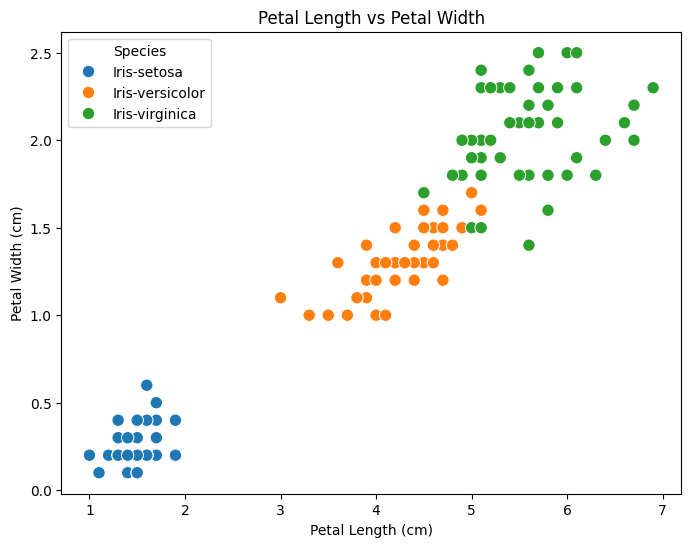

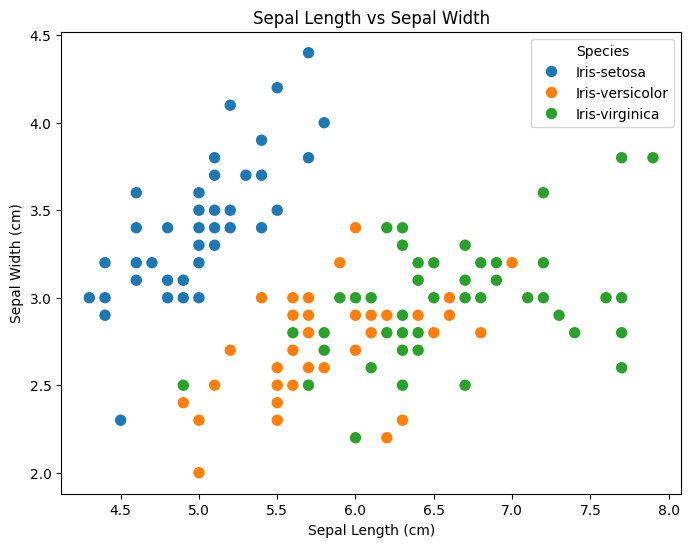

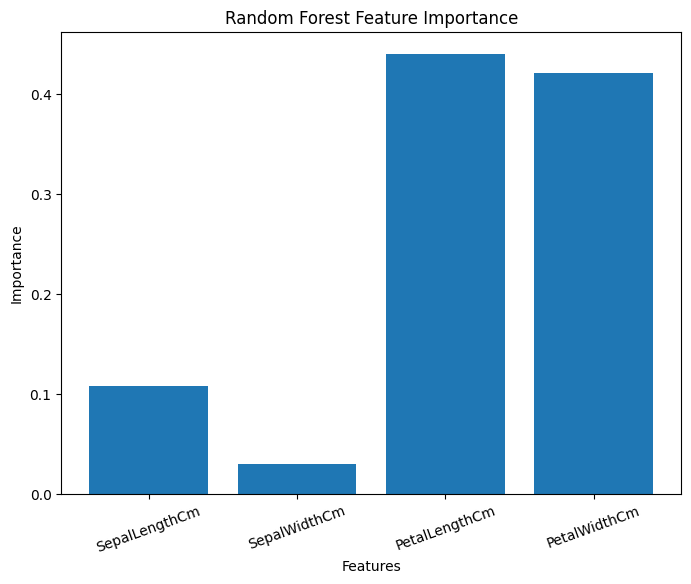

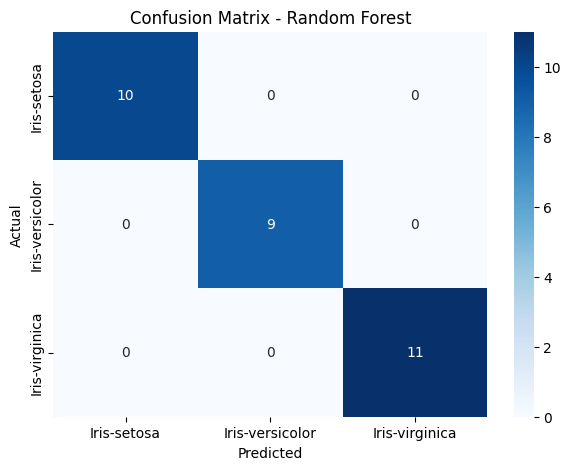

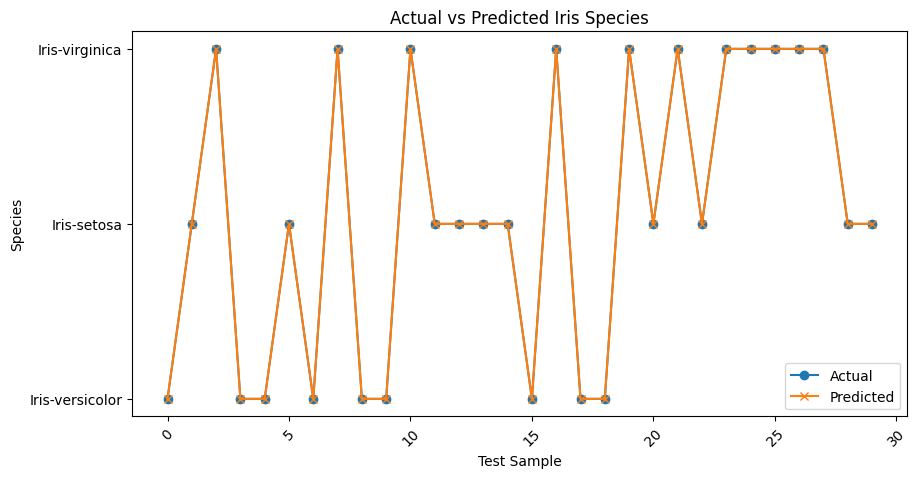

In [4]:
#IRIS DATASET IMPLEMENTATION USING RANDOM FOREST TREE
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load Iris dataset
data = pd.read_csv("/kaggle/input/datasets/uciml/iris/Iris.csv")

# Display dataset
print("Iris Dataset:")
print(data.head())

# Select features and target
X = data[["SepalLengthCm", "SepalWidthCm",
          "PetalLengthCm", "PetalWidthCm"]]

y = data["Species"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create Random Forest model
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train model
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nRandom Forest Classification")
print("Accuracy:", accuracy)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


# ==========================================
# GRAPH 1: Petal Length vs Petal Width
# ==========================================

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=data,
    x="PetalLengthCm",
    y="PetalWidthCm",
    hue="Species",
    s=80
)

plt.title("Petal Length vs Petal Width")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.show()


# ==========================================
# GRAPH 2: Sepal Length vs Sepal Width
# ==========================================

plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=data,
    x="SepalLengthCm",
    y="SepalWidthCm",
    hue="Species",
    s=80
)

plt.title("Sepal Length vs Sepal Width")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.show()


# ==========================================
# GRAPH 3: Feature Importance
# ==========================================

importance = model.feature_importances_

plt.figure(figsize=(8, 6))

plt.bar(X.columns, importance)

plt.title("Random Forest Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance")
plt.xticks(rotation=20)
plt.show()


# ==========================================
# GRAPH 4: Confusion Matrix
# ==========================================

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Random Forest")
plt.show()


# ==========================================
# GRAPH 5: Actual vs Predicted
# ==========================================

actual = pd.Series(y_test).reset_index(drop=True)
predicted = pd.Series(y_pred).reset_index(drop=True)

plt.figure(figsize=(10, 5))

plt.plot(actual, marker="o", label="Actual")
plt.plot(predicted, marker="x", label="Predicted")

plt.title("Actual vs Predicted Iris Species")
plt.xlabel("Test Sample")
plt.ylabel("Species")
plt.legend()
plt.xticks(rotation=45)
plt.show()